# BÀI THỰC HÀNH 1: XÂY DỰNG MẠNG NEURON ĐƠN GIẢN

<b>Hướng dẫn nộp bài:</b>
- Folder chứa toàn bộ source code, đặt tên là <b>\<MSSV\>.zip</b> với \<MSSV\> là MSSV của các bạn.
- Nộp qua course, giảng viên sẽ tạo submission sau mỗi buổi học.

Bộ dữ liệu sử dụng: MNIST dataset.

Link download: http://yann.lecun.com/exdb/mnist/.

In [1]:
import random, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import (
    accuracy_score, classification_report,
    precision_recall_fscore_support,
    confusion_matrix, ConfusionMatrixDisplay,
)

# Reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# Tải và chuẩn hoá MNIST 
tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)), 
])
train_full = datasets.MNIST("data", train=True,  download=True, transform=tf)
test_ds    = datasets.MNIST("data", train=False, download=True, transform=tf)

g = torch.Generator().manual_seed(42)
train_ds, val_ds = random_split(train_full, [54000, 6000], generator=g)

BATCH = 64
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,
                          generator=torch.Generator().manual_seed(42))
val_loader   = DataLoader(val_ds,  batch_size=256)
test_loader  = DataLoader(test_ds, batch_size=256)
print(f"Train: {len(train_ds):,} | Val: {len(val_ds):,} | Test: {len(test_ds):,}")

# Hàm dùng chung
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        total += loss.item() * x.size(0)
        n += x.size(0)
    return total / n

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total, n, preds, trues = 0.0, 0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total += criterion(logits, y).item() * x.size(0)
        n += x.size(0)
        preds.append(logits.argmax(dim=1).cpu())
        trues.append(y.cpu())
    return total / n, torch.cat(trues).numpy(), torch.cat(preds).numpy()

def fit(model, epochs=20, lr=0.1, verbose=True):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss = train_one_epoch(model, train_loader, criterion, optimizer)
        va_loss, yt, yp = evaluate(model, val_loader, criterion)
        va_acc = (yt == yp).mean()
        for k, v in zip(hist, (tr_loss, va_loss, va_acc)):
            hist[k].append(v)
        if verbose:
            print(f"epoch {ep:2d} | train_loss {tr_loss:.4f} | "
                  f"val_loss {va_loss:.4f} | val_acc {va_acc:.4f} | "
                  f"{time.time()-t0:.1f}s")
    return hist

def show_metrics(y_true, y_pred, title=""):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro")
    print(f"\n{'-'*50}")
    if title:
        print(f"  {title}")
        print(f"{'-'*50}")
    print(f"  Accuracy       : {acc:.4f}")
    print(f"  Precision macro: {p:.4f}")
    print(f"  Recall macro   : {r:.4f}")
    print(f"  F1 macro       : {f1:.4f}")
    print(f"{'-'*50}\n")
    print(classification_report(y_true, y_pred, digits=4))
    return acc, p, r, f1

def show_confusion(y_true, y_pred, title=""):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm)
    disp.plot(cmap="Blues", colorbar=False)
    disp.ax_.set_xlabel("Nhãn dự đoán")
    disp.ax_.set_ylabel("Nhãn thật")
    if title:
        plt.title(title)
    plt.tight_layout(); plt.show()
    off = cm.copy(); np.fill_diagonal(off, 0)
    print("Top 5 cặp nhầm lẫn (thật -> dự đoán):")
    for flat in off.ravel().argsort()[::-1][:5]:
        t, pr = divmod(flat, 10)
        print(f"  {t} -> {pr}: {off[t, pr]} ảnh")
    return cm

Device: cpu
Train: 54,000 | Val: 6,000 | Test: 10,000


### Bài 1: Xây dựng mô hình 1-layer MLP và hàm Softmax làm activation function. Huấn luyện mô hình này sử dụng SGD làm optimizer và đánh giá trên các độ đo accuracy, precision, recall và F1-macro. Đánh giá kết quả của mô hình với từng chữ số.

![image.png](attachment:image.png)

In [2]:
# Bài 1: 1-layer MLP - kiến trúc 784 -> 10, softmax tích hợp trong CrossEntropyLoss
set_seed(42)
model1 = nn.Sequential(
    nn.Flatten(),        
    nn.Linear(784, 10),  
)
print("Kiến trúc Bài 1:")
print(model1)
print(f"Số tham số: {sum(p.numel() for p in model1.parameters()):,}")

print("\n-- Huấn luyện Bài 1 (20 epoch, SGD lr=0.1) --")
hist1 = fit(model1, epochs=20, lr=0.1)

Kiến trúc Bài 1:
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=10, bias=True)
)
Số tham số: 7,850

-- Huấn luyện Bài 1 (20 epoch, SGD lr=0.1) --


epoch  1 | train_loss 0.3769 | val_loss 0.3477 | val_acc 0.9025 | 1.6s


epoch  2 | train_loss 0.3117 | val_loss 0.3475 | val_acc 0.9005 | 1.6s


epoch  3 | train_loss 0.3014 | val_loss 0.3261 | val_acc 0.9087 | 1.5s


epoch  4 | train_loss 0.2943 | val_loss 0.3266 | val_acc 0.9115 | 1.5s


...

epoch 16 | train_loss 0.2701 | val_loss 0.3456 | val_acc 0.9088 | 1.7s


epoch 17 | train_loss 0.2683 | val_loss 0.3748 | val_acc 0.8965 | 1.6s


epoch 18 | train_loss 0.2679 | val_loss 0.3349 | val_acc 0.9143 | 1.6s


epoch 19 | train_loss 0.2683 | val_loss 0.3283 | val_acc 0.9155 | 1.6s


epoch 20 | train_loss 0.2672 | val_loss 0.3391 | val_acc 0.9092 | 1.6s



--------------------------------------------------
  Bài 1 - 1-layer MLP (784 -> 10)
--------------------------------------------------
  Accuracy       : 0.9201
  Precision macro: 0.9191
  Recall macro   : 0.9193
  F1 macro       : 0.9189
--------------------------------------------------

              precision    recall  f1-score   support

           0     0.9514    0.9796    0.9653       980
           1     0.9717    0.9683    0.9700      1135
           2     0.9271    0.9002    0.9135      1032
           3     0.9033    0.9059    0.9046      1010
           4     0.8922    0.9521    0.9212       982
           5     0.8834    0.8744    0.8789       892
           6     0.9365    0.9551    0.9457       958
           7     0.9421    0.9173    0.9295      1028
           8     0.8631    0.8737    0.8684       974
           9     0.9200    0.8662    0.8923      1009

    accuracy                         0.9201     10000
   macro avg     0.9191    0.9193    0.9189     10000
wei

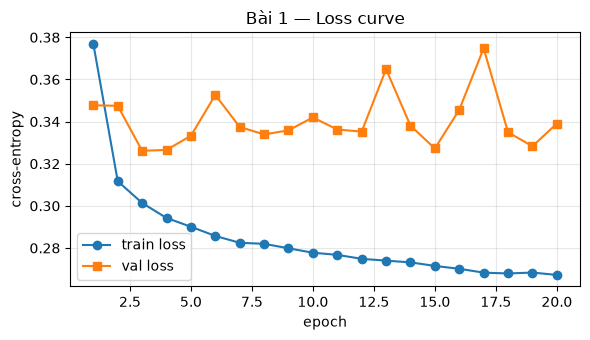

In [3]:
# Đánh giá trên tập test
_, y_true1, y_pred1 = evaluate(model1, test_loader, nn.CrossEntropyLoss())
acc1, p1, r1, f1_1 = show_metrics(y_true1, y_pred1,
                                   title="Bài 1 - 1-layer MLP (784 -> 10)")

# Đường cong loss
ep_range1 = range(1, len(hist1["train_loss"]) + 1)
plt.figure(figsize=(6, 3.5))
plt.plot(ep_range1, hist1["train_loss"], "o-", label="train loss")
plt.plot(ep_range1, hist1["val_loss"],   "s-", label="val loss")
plt.xlabel("epoch"); plt.ylabel("cross-entropy")
plt.title("Bài 1 - Loss curve")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

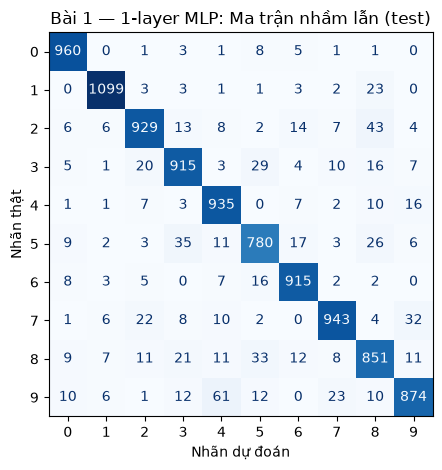

Top 5 cặp nhầm lẫn (thật -> dự đoán):
  9 -> 4: 61 ảnh
  2 -> 8: 43 ảnh
  5 -> 3: 35 ảnh
  8 -> 5: 33 ảnh
  7 -> 9: 32 ảnh


In [4]:
# Confusion matrix và phân tích
cm1 = show_confusion(y_true1, y_pred1,
                     title="Bài 1 - 1-layer MLP: Ma trận nhầm lẫn (test)")

### Bài 2: Xây dựng mô hình 3-layer MLP, hàm ReLU và hàm softmax làm activation function. Trong đó activation function cho 2 layer đầu là ReLU và activation function cho layer cuối là Softmax. Huấn luyện mô hình này sử dụng SGD làm optimizer và đánh giá trên các độ đo accuracy, precision, recall và F1-macro. Đánh giá kết quả của mô hình với từng chữ số.

![image.png](attachment:image.png)

In [5]:
# Bài 2: 3-layer MLP - ReLU x 2 lớp ẩn, Softmax ở lớp cuối (qua CrossEntropyLoss)
set_seed(42)
model2 = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256), nn.ReLU(),  
    nn.Linear(256, 128), nn.ReLU(),  
    nn.Linear(128, 10),              
)
print("Kiến trúc Bài 2:")
print(model2)
print(f"Số tham số: {sum(p.numel() for p in model2.parameters()):,}")

print("\n-- Huấn luyện Bài 2 (20 epoch, SGD lr=0.1) --")
hist2 = fit(model2, epochs=20, lr=0.1)

Kiến trúc Bài 2:
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=128, bias=True)
  (4): ReLU()
  (5): Linear(in_features=128, out_features=10, bias=True)
)
Số tham số: 235,146

-- Huấn luyện Bài 2 (20 epoch, SGD lr=0.1) --


epoch  1 | train_loss 0.3043 | val_loss 0.1559 | val_acc 0.9522 | 1.7s


epoch  2 | train_loss 0.1096 | val_loss 0.1082 | val_acc 0.9662 | 1.7s


epoch  3 | train_loss 0.0718 | val_loss 0.1004 | val_acc 0.9672 | 1.7s


epoch  4 | train_loss 0.0514 | val_loss 0.0852 | val_acc 0.9732 | 1.7s


...

epoch 16 | train_loss 0.0008 | val_loss 0.0785 | val_acc 0.9792 | 1.7s


epoch 17 | train_loss 0.0007 | val_loss 0.0792 | val_acc 0.9798 | 1.7s


epoch 18 | train_loss 0.0006 | val_loss 0.0815 | val_acc 0.9797 | 1.7s


epoch 19 | train_loss 0.0005 | val_loss 0.0820 | val_acc 0.9805 | 1.7s


epoch 20 | train_loss 0.0005 | val_loss 0.0834 | val_acc 0.9798 | 1.7s



--------------------------------------------------
  Bài 2 - 3-layer MLP (784 -> 256 -> 128 -> 10)
--------------------------------------------------
  Accuracy       : 0.9826
  Precision macro: 0.9826
  Recall macro   : 0.9824
  F1 macro       : 0.9825
--------------------------------------------------

              precision    recall  f1-score   support

           0     0.9848    0.9898    0.9873       980
           1     0.9930    0.9930    0.9930      1135
           2     0.9806    0.9806    0.9806      1032
           3     0.9803    0.9861    0.9832      1010
           4     0.9827    0.9827    0.9827       982
           5     0.9898    0.9776    0.9836       892
           6     0.9833    0.9812    0.9822       958
           7     0.9768    0.9815    0.9791      1028
           8     0.9754    0.9764    0.9759       974
           9     0.9791    0.9752    0.9772      1009

    accuracy                         0.9826     10000
   macro avg     0.9826    0.9824    0.9825

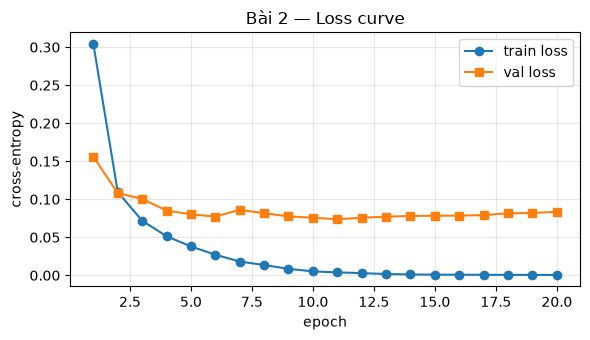

In [6]:
# Đánh giá trên tập test
_, y_true2, y_pred2 = evaluate(model2, test_loader, nn.CrossEntropyLoss())
acc2, p2, r2, f1_2 = show_metrics(y_true2, y_pred2,
                                   title="Bài 2 - 3-layer MLP (784 -> 256 -> 128 -> 10)")

# Đường cong loss
ep_range2 = range(1, len(hist2["train_loss"]) + 1)
plt.figure(figsize=(6, 3.5))
plt.plot(ep_range2, hist2["train_loss"], "o-", label="train loss")
plt.plot(ep_range2, hist2["val_loss"],   "s-", label="val loss")
plt.xlabel("epoch"); plt.ylabel("cross-entropy")
plt.title("Bài 2 - Loss curve")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

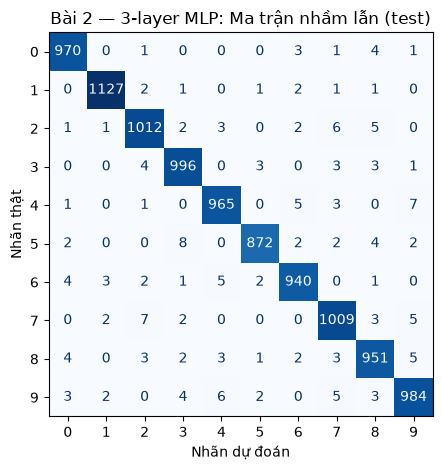

Top 5 cặp nhầm lẫn (thật -> dự đoán):
  5 -> 3: 8 ảnh
  4 -> 9: 7 ảnh
  7 -> 2: 7 ảnh
  9 -> 4: 6 ảnh
  2 -> 7: 6 ảnh


In [7]:
cm2 = show_confusion(y_true2, y_pred2,
                     title="Bài 2 - 3-layer MLP: Ma trận nhầm lẫn (test)")

In [8]:
print(f"{'':20s} {'Bài 1 (1-layer)':>16} {'Bài 2 (3-layer)':>16}")
print(f"{'Accuracy':20s} {acc1:>16.4f} {acc2:>16.4f}")
print(f"{'Precision (macro)':20s} {p1:>16.4f} {p2:>16.4f}")
print(f"{'Recall (macro)':20s} {r1:>16.4f} {r2:>16.4f}")
print(f"{'F1 (macro)':20s} {f1_1:>16.4f} {f1_2:>16.4f}")

                      Bài 1 (1-layer)  Bài 2 (3-layer)
Accuracy                       0.9201           0.9826
Precision (macro)              0.9191           0.9826
Recall (macro)                 0.9193           0.9824
F1 (macro)                     0.9189           0.9825
